<a href="https://colab.research.google.com/github/SarahAbuirmeileh/UNet_Brain_Segmentation/blob/UNet-model/notebooks/Brain_Tumor_Segmenation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain MRI Segmentation Utilizing the UNet Architecture

In [1]:
import kagglehub
from pathlib import Path

# Download latest version and store the path in DATA_PATH as a Path object
DATA_PATH = Path(kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation"))

print("Path to dataset files:", DATA_PATH)

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Path to dataset files: /kaggle/input/lgg-mri-segmentation


In [2]:
! apt install tree

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  tree
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 47.4 kB of archives.
After this operation, 111 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 tree amd64 2.1.1-2ubuntu3.24.04.2 [47.4 kB]
Fetched 47.4 kB in 1s (82.6 kB/s)
Selecting previously unselected package tree.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../tree_2.1.1-2ubuntu3.24.04.2_amd64.deb ...
Unpacking tree (2.1.1-2ubuntu3.24.04.2) ...
Setting up tree (2.1.1-2ubuntu3.24.04.2) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [3]:
! tree /kaggle/input/lgg-mri-segmentation


Streaming output truncated to the last 5000 lines.
        │   ├── TCGA_DU_7299_19910417_12.tif
        │   ├── TCGA_DU_7299_19910417_13_mask.tif
        │   ├── TCGA_DU_7299_19910417_13.tif
        │   ├── TCGA_DU_7299_19910417_14_mask.tif
        │   ├── TCGA_DU_7299_19910417_14.tif
        │   ├── TCGA_DU_7299_19910417_15_mask.tif
        │   ├── TCGA_DU_7299_19910417_15.tif
        │   ├── TCGA_DU_7299_19910417_16_mask.tif
        │   ├── TCGA_DU_7299_19910417_16.tif
        │   ├── TCGA_DU_7299_19910417_17_mask.tif
        │   ├── TCGA_DU_7299_19910417_17.tif
        │   ├── TCGA_DU_7299_19910417_18_mask.tif
        │   ├── TCGA_DU_7299_19910417_18.tif
        │   ├── TCGA_DU_7299_19910417_19_mask.tif
        │   ├── TCGA_DU_7299_19910417_19.tif
        │   ├── TCGA_DU_7299_19910417_1_mask.tif
        │   ├── TCGA_DU_7299_19910417_1.tif
        │   ├── TCGA_DU_7299_19910417_20_mask.tif
        │   ├── TCGA_DU_7299_19910417_20.tif
        │   ├── TCGA_DU_7299_19910417_21_mask.tif
 

In [4]:
import os
import glob
import numpy as np
from PIL import Image

# Count total files, images, and masks using the pathlib DATA_PATH variable
all_files = list(DATA_PATH.rglob('*'))
tif_files = [str(f) for f in all_files if f.is_file() and f.suffix == '.tif']
masks = [f for f in tif_files if '_mask' in f]
images = [f for f in tif_files if '_mask' not in f]

# Get unique subjects using DATA_PATH (folders within kaggle_3m)
subject_dirs = [str(d) for d in (DATA_PATH / 'kaggle_3m').glob('*') if d.is_dir() and d.name != 'data']

# Get metadata from a sample image
sample_img_path = images[0]
sample_img = Image.open(sample_img_path)
sample_arr = np.array(sample_img)

print(f"=== Dataset Overview: {DATA_PATH.name} ===\n")
print(f"Total Directories (Subjects): {len(subject_dirs)}")
print(f"Total Images (.tif): {len(images)}")
print(f"Total Masks (.tif): {len(masks)}")
print(f"Sample Image Shape: {sample_arr.shape}")
print(f"Sample Image Data Type: {sample_arr.dtype}\n")

=== Dataset Overview: lgg-mri-segmentation ===

Total Directories (Subjects): 110
Total Images (.tif): 7858
Total Masks (.tif): 7858
Sample Image Shape: (256, 256, 3)
Sample Image Data Type: uint8



Total available images (properly ordered) in this path: 58


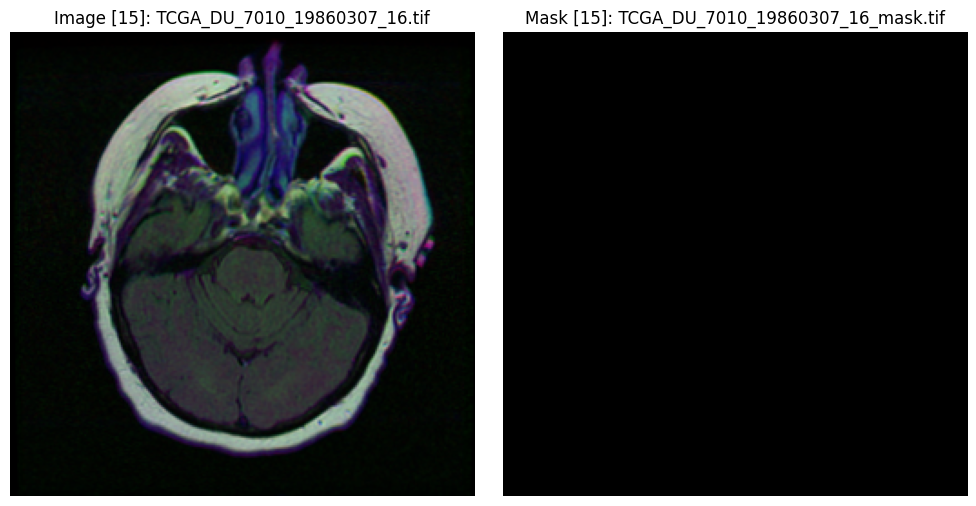

In [5]:
import os
import glob
import re
import matplotlib.pyplot as plt
from PIL import Image

def get_slice_number(filename):
    # Helper function to extract slice number from file name to allow natural numeric sorting
    match = re.search(r'_(	*\d+)\.tif$', filename)
    return int(match.group(1)) if match else 0

def visualize_by_index(folder_path, index):
    # Find all .tif files in the specified path
    all_files = glob.glob(os.path.join(folder_path, '**/*.tif'), recursive=True)

    # Filter to get only the original images (excluding masks)
    img_files = [f for f in all_files if '_mask' not in f]

    # Sort the slices by their numerical value instead of alphabetical value
    img_files = sorted(img_files, key=get_slice_number)

    num_images = len(img_files)
    print(f"Total available images (properly ordered) in this path: {num_images}")

    if num_images == 0:
        print(f"No images found in path: {folder_path}")
        return

    # Validate index range
    if index < 0 or index >= num_images:
        print(f"Error: Index {index} is out of bounds. Please choose between 0 and {num_images - 1}.")
        return

    # Select the image at the given index
    img_path = img_files[index]
    mask_path = img_path.replace('.tif', '_mask.tif')

    # Load image and mask
    img = Image.open(img_path)
    if os.path.exists(mask_path):
        mask = Image.open(mask_path)
    else:
        mask = None

    # Plot side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original Image
    axes[0].imshow(img)
    axes[0].set_title(f"Image [{index}]: {os.path.basename(img_path)}")
    axes[0].axis('off')

    # Mask
    if mask is not None:
        axes[1].imshow(mask, cmap='gray')
        axes[1].set_title(f"Mask [{index}]: {os.path.basename(mask_path)}")
    else:
        axes[1].text(0.5, 0.5, 'No Mask Found', horizontalalignment='center', verticalalignment='center')
        axes[1].set_title("Mask (Missing)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Example usage: visualize slice index 15
sample_folder = str(DATA_PATH / 'kaggle_3m/TCGA_DU_7010_19860307')
visualize_by_index(sample_folder, 15)

Total available subjects: 110
Selected Subject [1]: TCGA_CS_4942_19970222
Found 20 brain slices. Generating visualization...


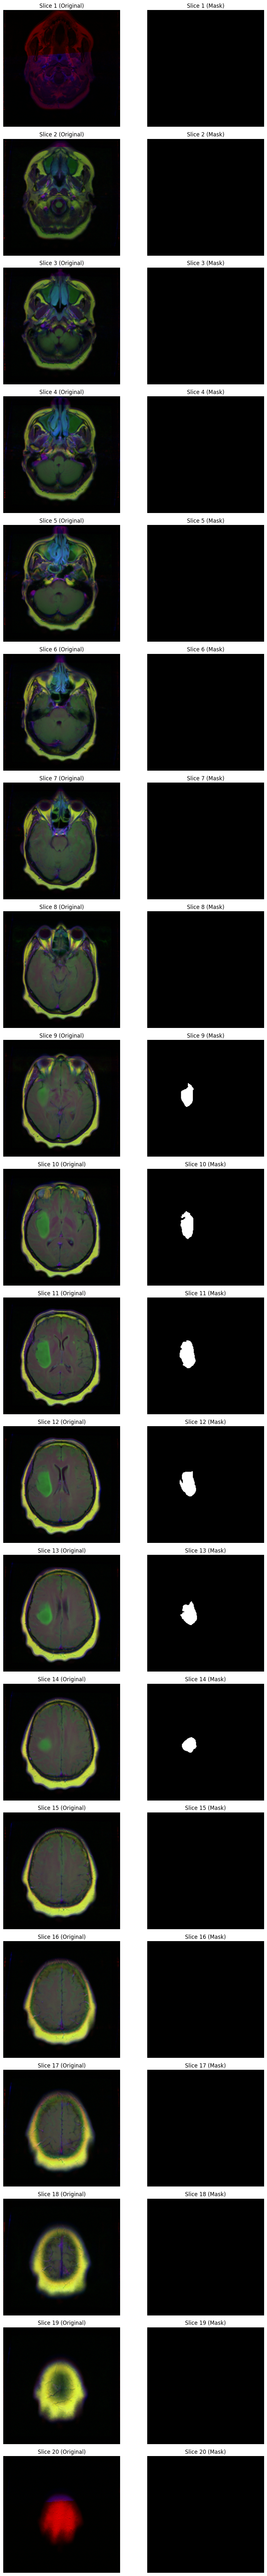

In [6]:
import os
import glob
import re
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def get_slice_number(filename):
    # Helper to extract the trailing slice number (e.g., '_15.tif' -> 15) for numerical sorting
    match = re.search(r'_(\d+)\.tif$', filename)
    return int(match.group(1)) if match else 0

def visualize_subject_by_index(path_obj, subject_index):
    # 1. Find all subject directories (folders within kaggle_3m or main path)
    # Each folder containing brain MRI scans represents a single patient/subject
    subject_folders = sorted([
        str(d) for d in (path_obj / 'kaggle_3m').glob('*')
        if d.is_dir() and d.name != 'data'
    ])

    num_subjects = len(subject_folders)
    print(f"Total available subjects: {num_subjects}")

    # Validate subject index
    if subject_index < 0 or subject_index >= num_subjects:
        print(f"Error: Subject index {subject_index} is out of bounds. Please choose between 0 and {num_subjects - 1}.")
        return

    chosen_subject_path = subject_folders[subject_index]
    subject_name = os.path.basename(chosen_subject_path)
    print(f"Selected Subject [{subject_index}]: {subject_name}")

    # 2. Find and naturally sort all slice images inside this subject's folder
    all_files = glob.glob(os.path.join(chosen_subject_path, '*.tif'))
    img_files = sorted([f for f in all_files if '_mask' not in f], key=get_slice_number)

    num_slices = len(img_files)
    print(f"Found {num_slices} brain slices. Generating visualization...")

    if num_slices == 0:
        return

    # 3. Create a grid showing all slices and masks side-by-side
    fig, axes = plt.subplots(num_slices, 2, figsize=(10, 4 * num_slices))

    # Ensure axes is indexed correctly even if there's only 1 slice
    if num_slices == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, img_path in enumerate(img_files):
        mask_path = img_path.replace('.tif', '_mask.tif')

        # Open files
        img = Image.open(img_path)
        mask = Image.open(mask_path) if os.path.exists(mask_path) else None

        # Display scan
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Slice {get_slice_number(img_path)} (Original)")
        axes[i, 0].axis('off')

        # Display mask
        if mask is not None:
            axes[i, 1].imshow(mask, cmap='gray')
            axes[i, 1].set_title(f"Slice {get_slice_number(img_path)} (Mask)")
        else:
            axes[i, 1].text(0.5, 0.5, 'No Mask', ha='center', va='center')
            axes[i, 1].set_title(f"Slice {get_slice_number(img_path)} (Mask Missing)")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Let's visualize all slices for the subject at index 1 using DATA_PATH
visualize_subject_by_index(DATA_PATH, 1)



### 0. Importing Libraries

In [7]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline

import cv2
from tqdm import tqdm_notebook, tnrange
from glob import glob
from itertools import chain
from skimage.io import imread, imshow, concatenate_images
from skimage.transform import resize
from skimage.morphology import label
from sklearn.model_selection import train_test_split
from IPython.display import Image, display

import tensorflow as tf
from skimage.color import rgb2gray
from tensorflow.keras import Input
from tensorflow.keras.models import Model, load_model, save_model
from tensorflow.keras.layers import Input, Activation, BatchNormalization, Dropout, Lambda, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate
from tensorflow.keras.optimizers.legacy import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from tensorflow.keras import backend as K
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [10]:
import cv2

# Read a sample image from the training file list and print its shape
for i in range (100):
  random_index = random.randint(0, len(image_filename_train) - 1)
  sample_img = cv2.imread(image_filename_train[random_index])
  print("Sample Image Shape:", sample_img.shape)

Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image Shape: (256, 256, 3)
Sample Image S


> All images with the same shape [256, 256, 3]




In [11]:
im_width = 256
im_height = 256

image_filename_train = []

# Using native pathlib glob on the DATA_PATH object directly
mask_files = [str(f) for f in (DATA_PATH / 'kaggle_3m').glob('*/*_mask*')]

for i in mask_files:
    image_filename_train.append(i.replace('_mask',''))

len(image_filename_train), image_filename_train[:10]

(3929,
 ['/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_56.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_8.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_34.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_33.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_43.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_39.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_7.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_31.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_6.tif',
  '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_1986

In [12]:
shapes = set()
for path in image_filename_train:
    img = cv2.imread(path)
    if img is not None:
        shapes.add(img.shape)

print(f"Total unique image shapes across all {len(image_filename_train)} files:", list(shapes))

Total unique image shapes across all 3929 files: [(256, 256, 3)]


In [13]:
# displays MRI images with their corresponding tumor masks overlaid on top, arranged in a grid so you can visualize multiple examples at once.

def plot_from_img_path(rows, columns, list_img_path, list_mask_path):
    fig = plt.figure(figsize  = (12,12))
    for i in range(1, rows * columns + 1):
        fig.add_subplot(rows, columns, i)
        img_path = list_img_path[i]
        mask_path = list_mask_path[i]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path)
        plt.imshow(image)
        plt.imshow(mask, alpha=0.4)
    plt.show()

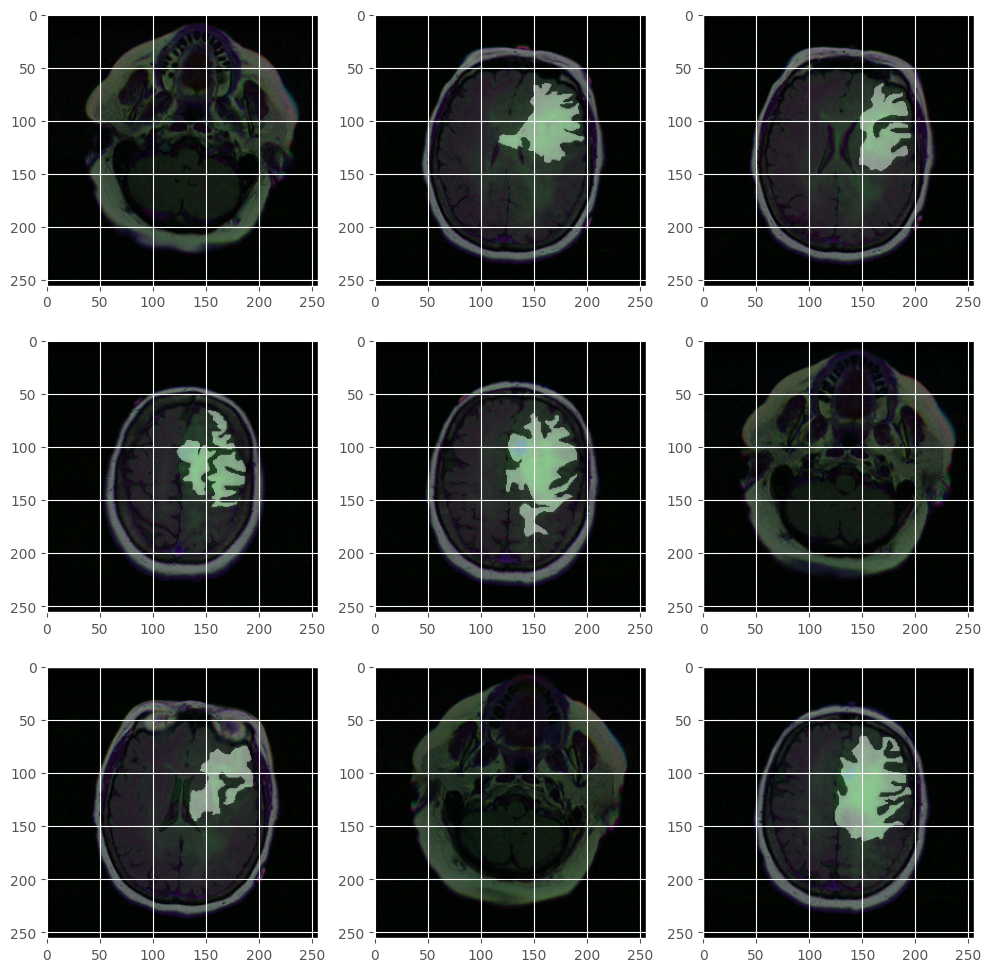

In [14]:
plot_from_img_path(3, 3, image_filename_train, mask_files)

## 1. Preprocessing the Data

In [15]:
df = pd.DataFrame(data = {'image_filename_train': image_filename_train, 'mask': mask_files})
df_train, df_test = train_test_split(df, test_size = 0.05)
df_train, df_val = train_test_split(df_train, test_size = 0.05)

In [16]:
print(df_train.shape)
print(df_val.shape)
print(df_test.shape)

(3545, 2)
(187, 2)
(197, 2)


In [17]:
def train_generator(
    data_frame,
    batch_size,
    augmentation_dict,
    image_color_mode="rgb",
    mask_color_mode="grayscale",
    image_save_prefix="image",
    mask_save_prefix="mask",
    save_to_dir=None,
    target_size=(256, 256),
    seed=1,
):

    image_datagen = ImageDataGenerator(**augmentation_dict)
    mask_datagen = ImageDataGenerator(**augmentation_dict)

    image_generator = image_datagen.flow_from_dataframe(
        data_frame,
        x_col="image_filename_train",
        class_mode=None,
        color_mode=image_color_mode,
        target_size=target_size,
        batch_size=batch_size,
        save_to_dir=save_to_dir,
        save_prefix=image_save_prefix,
        seed=seed,
    )

    mask_generator = mask_datagen.flow_from_dataframe(
        data_frame,
        x_col="mask",
        class_mode=None,
        color_mode=mask_color_mode,
        target_size=target_size,
        batch_size=batch_size,
        save_to_dir=save_to_dir,
        save_prefix=mask_save_prefix,
        seed=seed,
    )

    train_gen = zip(image_generator, mask_generator)

    # Final return Tuple after image Normalization and Diagnostics
    for (img, mask) in train_gen:
        img, mask = normalize_and_diagnose(img, mask)
        yield (img, mask)

In [18]:
def normalize_and_diagnose(img, mask):
    img = img / 255
    mask = mask / 255
    mask[mask > 0.5] = 1
    mask[mask <= 0.5] = 0
    return(img, mask)

def dice_coefficients(y_true, y_pred, smooth=100):
    y_true_flatten = K.flatten(y_true)
    y_pred_flatten = K.flatten(y_pred)

    intersection = K.sum(y_true_flatten * y_pred_flatten)
    union = K.sum(y_true_flatten) + K.sum(y_pred_flatten)
    return (2 * intersection + smooth) / (union + smooth)

def dice_coefficients_loss(y_true, y_pred, smooth=100):
    return -dice_coefficients(y_true, y_pred, smooth)

def iou(y_true, y_pred, smooth=100):
    intersection = K.sum(y_true * y_pred)
    sum = K.sum(y_true + y_pred)
    iou = (intersection + smooth) / (sum - intersection + smooth)
    return iou

def jaccard_distance(y_true, y_pred):
    y_true_flatten = K.flatten(y_true)
    y_pred_flatten = K.flatten(y_pred)
    return -iou(y_true_flatten, y_pred_flatten)

## UNet Architecture

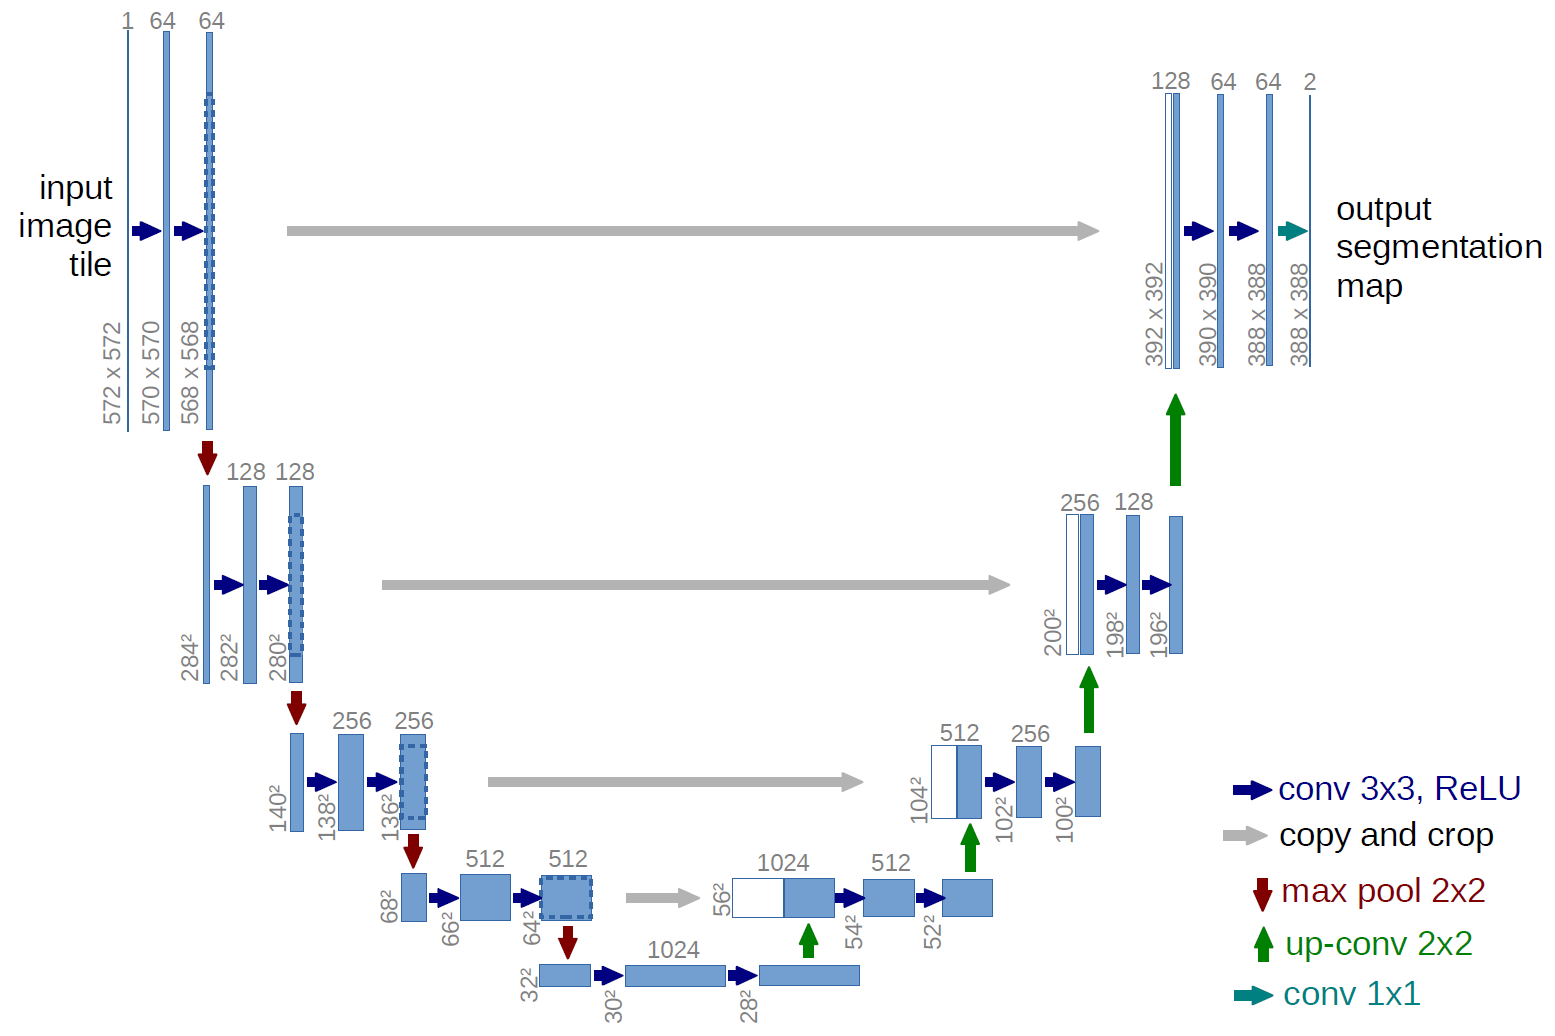

In [19]:
def unet(input_size=(im_width, im_height, 3)):

    inputs = Input(input_size)

    # First DownConvolution / Encoder Leg will begin, so start with Conv2D
    conv1 = Conv2D(filters=64, kernel_size=(3, 3), padding="same")(inputs)
    bn1 = Activation("relu")(conv1)
    conv1 = Conv2D(filters=64, kernel_size=(3, 3), padding="same")(bn1)
    bn1 = BatchNormalization(axis=3)(conv1)
    bn1 = Activation("relu")(bn1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(bn1)
    # First DownSampling
    conv2 = Conv2D(filters=128, kernel_size=(3, 3), padding="same")(pool1)
    bn2 = Activation("relu")(conv2)
    conv2 = Conv2D(filters=128, kernel_size=(3, 3), padding="same")(bn2)
    bn2 = BatchNormalization(axis=3)(conv2)
    bn2 = Activation("relu")(bn2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(bn2)
    #Second DownSampling
    conv3 = Conv2D(filters=256, kernel_size=(3, 3), padding="same")(pool2)
    bn3 = Activation("relu")(conv3)
    conv3 = Conv2D(filters=256, kernel_size=(3, 3), padding="same")(bn3)
    bn3 = BatchNormalization(axis=3)(conv3)
    bn3 = Activation("relu")(bn3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(bn3)
    # Third DownSampling
    conv4 = Conv2D(filters=512, kernel_size=(3, 3), padding="same")(pool3)
    bn4 = Activation("relu")(conv4)
    conv4 = Conv2D(filters=512, kernel_size=(3, 3), padding="same")(bn4)
    bn4 = BatchNormalization(axis=3)(conv4)
    bn4 = Activation("relu")(bn4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(bn4)

    conv5 = Conv2D(filters=1024, kernel_size=(3, 3), padding="same")(pool4)
    bn5 = Activation("relu")(conv5)
    conv5 = Conv2D(filters=1024, kernel_size=(3, 3), padding="same")(bn5)
    bn5 = BatchNormalization(axis=3)(conv5)
    bn5 = Activation("relu")(bn5)

    up6 = concatenate([Conv2DTranspose(512, kernel_size=(2, 2), strides=(2, 2), padding="same")(bn5), conv4], axis=3)
    """ After every concatenation we again apply two consecutive regular convolutions so that the model can learn to assemble a more precise output """
    conv6 = Conv2D(filters=512, kernel_size=(3, 3), padding="same")(up6)
    bn6 = Activation("relu")(conv6)
    conv6 = Conv2D(filters=512, kernel_size=(3, 3), padding="same")(bn6)
    bn6 = BatchNormalization(axis=3)(conv6)
    bn6 = Activation("relu")(bn6)

    up7 = concatenate([Conv2DTranspose(256, kernel_size=(2, 2), strides=(2, 2), padding="same")(bn6),conv3], axis=3)
    conv7 = Conv2D(filters=256, kernel_size=(3, 3), padding="same")(up7)
    bn7 = Activation("relu")(conv7)
    conv7 = Conv2D(filters=256, kernel_size=(3, 3), padding="same")(bn7)
    bn7 = BatchNormalization(axis=3)(conv7)
    bn7 = Activation("relu")(bn7)

    up8 = concatenate([Conv2DTranspose(128, kernel_size=(2, 2), strides=(2, 2), padding="same")(bn7),conv2], axis=3)
    conv8 = Conv2D(filters=128, kernel_size=(3, 3), padding="same")(up8)
    bn8 = Activation("relu")(conv8)
    conv8 = Conv2D(filters=128, kernel_size=(3, 3), padding="same")(bn8)
    bn8 = BatchNormalization(axis=3)(conv8)
    bn8 = Activation("relu")(bn8)

    up9 = concatenate([Conv2DTranspose(64, kernel_size=(2, 2), strides=(2, 2), padding="same")(bn8),conv1],axis=3)
    conv9 = Conv2D(filters=64, kernel_size=(3, 3), padding="same")(up9)
    bn9 = Activation("relu")(conv9)
    conv9 = Conv2D(filters=64, kernel_size=(3, 3), padding="same")(bn9)
    bn9 = BatchNormalization(axis=3)(conv9)
    bn9 = Activation("relu")(bn9)

    conv10 = Conv2D(filters=1, kernel_size=(1, 1), activation="sigmoid")(bn9)

    return Model(inputs=[inputs], outputs=[conv10])

## Training the UNet model

In [ ]:
from tensorflow.keras.optimizers import Adam

EPOCHS = 100
# Lowered BATCH_SIZE from 32 to 16 to avoid Out of Memory (OOM) errors
BATCH_SIZE = 16
learning_rate = 1e-4

train_generator_args = dict(rotation_range=0.2,
                            width_shift_range=0.05,
                            height_shift_range=0.05,
                            shear_range=0.05,
                            zoom_range=0.05,
                            horizontal_flip=True,
                            fill_mode='nearest')
train_gen = train_generator(df_train, BATCH_SIZE,
                                train_generator_args,
                                target_size=(im_height, im_width))

test_gener = train_generator(df_val, BATCH_SIZE,
                                dict(),
                                target_size=(im_height, im_width))

model = unet(input_size=(im_height, im_width, 3))

# Use modern Adam optimizer and learning_rate argument
opt = Adam(learning_rate=learning_rate, beta_1=0.9, beta_2=0.999, amsgrad=False)
model.compile(optimizer=opt, loss=dice_coefficients_loss, metrics=["binary_accuracy", iou, dice_coefficients])

# Updated the extension to .keras to satisfy Keras 3 requirements
callbacks = [ModelCheckpoint('unet_brain_mri_seg.keras', verbose=1, save_best_only=True)]

# Using floor division '//' to ensure steps are integers
history = model.fit(train_gen,
                    steps_per_epoch=len(df_train) // BATCH_SIZE,
                    epochs=EPOCHS,
                    callbacks=callbacks,
                    validation_data = test_gener,
                    validation_steps=len(df_val) // BATCH_SIZE)

### Plotting the metrics

In [ ]:
history_post_training = history.history

train_dice_coeff_list = history_post_training['dice_coefficients']
test_dice_coeff_list = history_post_training['val_dice_coefficients']

train_jaccard_list = history_post_training['iou']
test_jaccard_list = history_post_training['val_iou']

train_loss_list = history_post_training['loss']
test_loss_list = history_post_training['val_loss']

plt.figure(1)
plt.plot(test_loss_list, 'b-')
plt.plot(train_loss_list, 'r-')

plt.xlabel('iterations')
plt.ylabel('loss')
plt.title('loss graph', fontsize=12)

plt.figure(2)
plt.plot(train_dice_coeff_list, 'b-')
plt.plot(test_dice_coeff_list, 'r-')

plt.xlabel('iterations')
plt.ylabel('accuracy')
plt.title('Accuracy graph', fontsize=12)
plt.show()

In [ ]:
display(Image(filename='Loss Graph.png'))

### Evaluating the Model

In [ ]:
model = load_model('unet_brain_mri_seg.hdf5', custom_objects={'dice_coef_loss': dice_coefficients_loss, 'iou': iou, 'dice_coef': dice_coefficients})

In [ ]:
test_gen = train_generator(df_test, BATCH_SIZE, dict(), target_size=(im_height,im_width))

results = model.evaluate(test_gen, steps = len(df_test)/BATCH_SIZE)
print('Test Loss', results[0])
print('Test IOU', results[1])
print('Test Dice Coeff', results[2])

### Moment of Truth

In [ ]:
for i in range(20):
    index = np.random.randint(1, len(df_test.index))
    img = cv2.imread(df_test['image_filename_train'].iloc[index])
    img = cv2.resize(img, (im_height,im_width))
    img = img/255
    img = img[np.newaxis, : ,:, :]
    pred_img = model.predict(img)

    plt.figure(figsize=(12,12))
    plt.subplot(1, 3, 1)
    plt.imshow(np.squeeze(img))
    plt.title("Original Image")
    plt.subplot(1, 3, 2)
    plt.imshow(np.squeeze(cv2.imread(df_test['mask'].iloc[index])))
    plt.title("Original Mask")
    plt.subplot(1, 3, 3)
    plt.imshow(np.squeeze(pred_img) > 0.5)
    plt.title("Prediction")
    plt.show()